In [1]:
import os
import sys
import numpy as np
from astropy.table import Table, Column
import glob

import matplotlib.pyplot as pl

import astropy.constants as const 
import astropy.units as u

import hdf5_tools.hdf5_tools as hdf5
 
%config InlineBackend.figure_format="retina"
%config Completer.use_jedi = False

In [2]:
ls ./data/Power_Spec

sigmacdm_1.00_+0.000_1.00.spline.1
sigmacdm_1.00_+0.000_1.00.spline.3_0.25_0.0450


In [3]:
!head ./data/pk_Mill.dat.spline

 200
 1. 79.17815 0. -0.04213867 0.
 1.2315506 78.48991 3.016063 -0.042437844 0.0012990541
 1.5167168 77.80622 1.1641464 -0.04273578 0.00049475126
 1.8679136 77.121765 0.9957919 -0.043035816 0.00040619733
 2.30043 76.43935 0.5945401 -0.04333834 0.00027465317
 2.833096 75.75816 0.40445176 -0.04364064 0.00016087806
 3.4891014 75.07816 0.26712084 -0.04394617 0.00012487352
 4.2970047 74.40057 0.17310674 -0.04425077 0.00007568319
 5.291979 73.72435 0.114959225 -0.04455606 0.000047648417


In [4]:
spl_mil = np.genfromtxt('./data/pk_Mill.dat.spline',skip_header=1)
spl_mil.shape

(200, 5)

In [5]:
spl_eh = np.genfromtxt('./data/Power_Spec/sigmacdm_1.00_+0.000_1.00.spline.3_0.25_0.0450',skip_header=1)
spl_eh.shape

(200, 5)

In [6]:
spl_bbks = np.genfromtxt('./data/Power_Spec/sigmacdm_1.00_+0.000_1.00.spline.1',skip_header=1)
spl_bbks.shape

(200, 5)

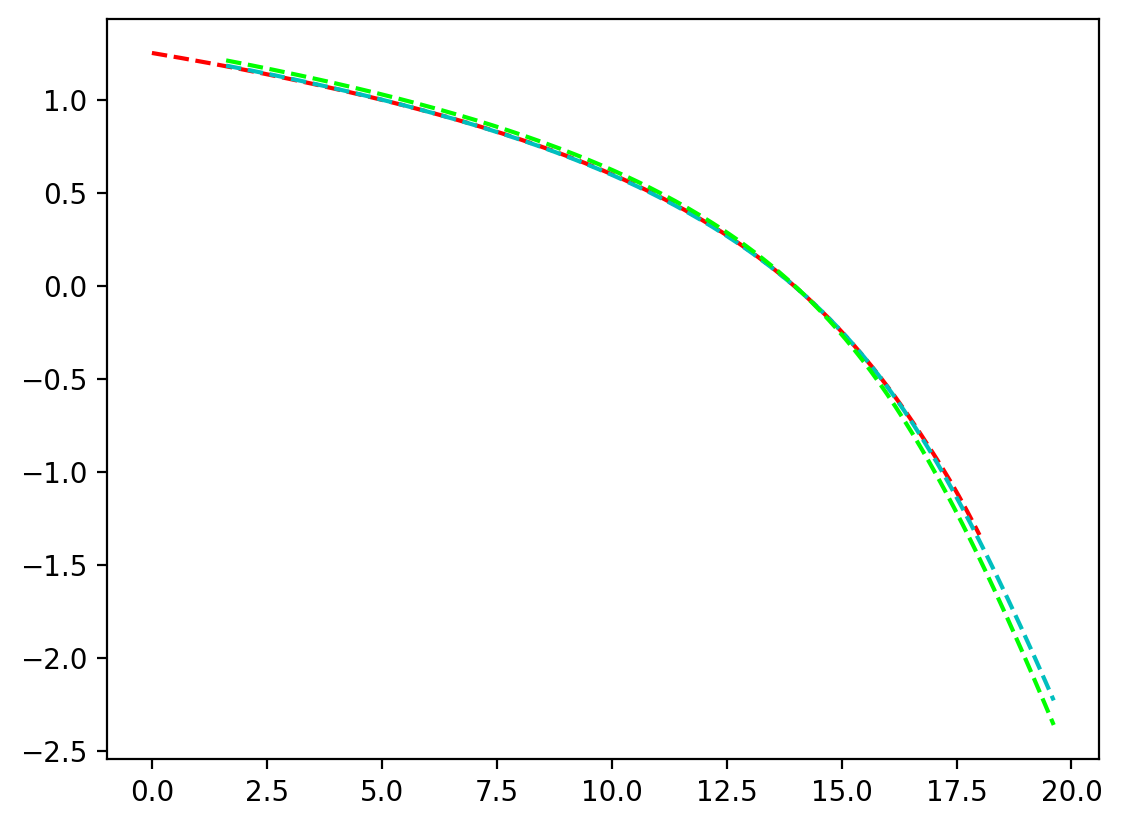

In [7]:
sclm_eh =   2.43135653E-02
scla_eh =   0.340618610

sclm_mil =   1.00000000
scla_mil =   0.225111574

sclm_bbks =   2.43135653E-02
scla_bbks =   0.231277660

lf = np.log10

#pl.plot(lf(spl_mil[:,0]),lf(spl_mil[:,1]),c='orange',label='Mil')
#pl.plot(lf(spl_eh[:,0]),lf(spl_eh[:,1]),c='b',label='EH')
#pl.plot(lf(spl_bbks[:,0]),lf(spl_bbks[:,1]),c='g',label='BBKS')

pl.plot(lf(spl_mil[:,0])  - lf(sclm_mil)  , lf(spl_mil[:,1])  + lf(scla_mil),  c='r',label='Mil (RS)',ls='--')
pl.plot(lf(spl_eh[:,0])   - lf(sclm_eh)   , lf(spl_eh[:,1])   + lf(scla_eh),   c='c',label='EH (RS)',ls='--')
pl.plot(lf(spl_bbks[:,0]) - lf(sclm_bbks) , lf(spl_bbks[:,1]) + lf(scla_bbks), c='lime',label='BBKS (RS)',ls='--')

In [8]:
# M s=sigma(M) d^2s/dm^2  a=dlns/dlnm  d^2a/dm^2

In [9]:
!head data/pk_Mill.dat

# k (h Mpc^{-1})     P(k) h^{3} Mpc^{-3} 
 1.0E-6 6.2111907
 1.0280447E-6 6.385382
 1.0568759E-6 6.5644583
 1.0865157E-6 6.7485556
 1.1169867E-6 6.937818
 1.1483123E-6 7.132387
 1.1805164E-6 7.3324122
 1.2136237E-6 7.5380482
 1.2476594E-6 7.74945


In [10]:
d_mil_tab = np.genfromtxt('data/pk_Mill.dat')

In [11]:
k_eh  = hdf5.read_hdf5_data('./output_tree_eh_pk_quick.001.hdf5','/Powerspec/k')
pk_eh = hdf5.read_hdf5_data('./output_tree_eh_pk_quick.001.hdf5','/Powerspec/Pk')

In [12]:
k_tb  = hdf5.read_hdf5_data('./output_tree_tabulated_pk_quick.001.hdf5','/Powerspec/k')
pk_tb = hdf5.read_hdf5_data('./output_tree_tabulated_pk_quick.001.hdf5','/Powerspec/Pk')

In [13]:
k_bb  = hdf5.read_hdf5_data('./output_tree_bbks_pk_quick.001.hdf5','/Powerspec/k')
pk_bb = hdf5.read_hdf5_data('./output_tree_bbks_pk_quick.001.hdf5','/Powerspec/Pk')

In [14]:
omega0 = 0.25
h      = 0.73
gamma  = omega0*h

In [15]:
gamma

0.1825

We have

$\sigma_8^2 = \frac{1}{2\pi} \int P(k) W^2(k,R) k^2 dk$

and

$P(k) = A k^n T^2(k)$.

Define $a = \frac{\sigma_{8}^2}{\sigma_{8,\star}^2}$, where $\sigma_{8,\star}$ is the normalization for $\Omega_0 = h = \gamma = 1$ and $\sigma_{8}$ is the desired normalization. 

Define $\gamma = \Omega_0 h$, such that scales in the power spectrum transform as $k = \gamma k_\star$.

Define the multiplicative factor $s$ such that $\sigma_{8} = s \sigma_{8,\star}$. 

We have $s = \frac{\gamma^3}{\Omega_0}$.

Thus, given an unormalized power spectrum $P^{*}(k) = A^{*} k^n T^2(k)$.


$\sigma_8^2 = \frac{1}{2\pi} \int A k^n T^2 W^2 k^2 dk$

Hence 

$s^2 (\sigma_8^*)^2 \propto bA^{*} \gamma^{(2+n+1)} \int T^2 W^2 k_*^{(2+n)} dk_*$




In [16]:
import hmf
import astropy.cosmology as cmo

lcdm_ref = cmo.FlatLambdaCDM(100,1.0,Ob0=0.0,Tcmb0=0)


lcdm_nob = cmo.FlatLambdaCDM(73,0.25,Ob0=0.0,Tcmb0=2.73)

lcdm = cmo.FlatLambdaCDM(73,0.25,Ob0=0.045,Tcmb0=2.73)

T_bbks = hmf.density_field.transfer.Transfer(cosmo_model=lcdm,
                                             sigma_8=0.9,n=1,
                                             transfer_model=hmf.density_field.transfer_models.BBKS)

T_bbks_ref = hmf.density_field.transfer.Transfer(cosmo_model=lcdm_ref,
                                             sigma_8=1.0,n=1,
                                             transfer_model=hmf.density_field.transfer_models.BBKS)

T_bbksb = hmf.density_field.transfer.Transfer(cosmo_model=lcdm_nob,
                                             sigma_8=0.9,n=1,
                                             transfer_model=hmf.density_field.transfer_models.BBKS)

T_eh = hmf.density_field.transfer.Transfer(cosmo_model=lcdm_nob,
                                           sigma_8=0.9,n=1,
                                           transfer_model=hmf.density_field.transfer_models.EH_NoBAO)

T_ehb = hmf.density_field.transfer.Transfer(cosmo_model=lcdm,
                                           sigma_8=0.9,n=1,
                                           transfer_model=hmf.density_field.transfer_models.EH_BAO)

From HMF docs for BBKS:

The fit is given as

$$
T(k) = \frac{\ln(1+aq)}{aq}\left(1 + bq + (cq)^2 + (dq)^3 + (eq)^4\right)^{-1/4}
$$

where

$$
q = \frac{k}{\Gamma} \exp\left(\Omega_{b,0} + \frac{\sqrt{2h}\Omega_{b,0}}{\Omega_{m,0}}\right)
$$

and
    
$$\Gamma = \Omega_{m,0} h$$

In [17]:
T_ehb.quantities_available()

['_growth_factor_fn',
 '_normalisation',
 '_power0',
 '_unn_sig8',
 '_unnormalised_lnT',
 '_unnormalised_power',
 'cosmo',
 'delta_k',
 'growth',
 'growth_factor',
 'k',
 'mean_density0',
 'nonlinear_delta_k',
 'nonlinear_power',
 'power',
 'transfer',
 'transfer_function']

In [18]:
hmf.density_field.transfer.Transfer??

Init signature: hmf.density_field.transfer.Transfer(*args, **kwargs)
Source:        
class Transfer(cosmo.Cosmology):
    """
    A transfer function framework.

    The purpose of this :class:`hmf._frameworks.Framework` is to calculate
    transfer functions, power spectra and several tightly associated
    quantities given a basic model for the transfer function.

    As in all frameworks, to update parameters optimally, use the
    :meth:`update` method. All output quantities are calculated only when needed
    (but stored after first calculation for quick access).

    In addition to the parameters directly passed to this class, others are available
    which are passed on to its superclass. To read a standard documented list of (all)
    parameters, use ``Transfer.parameter_info()``. If you want to just see the plain
    list of available parameters, use ``Transfer.get_all_parameters()``.To see the
    actual defaults for each parameter, use ``Transfer.get_all_parameter_defaults()

1.0


(2.0, 11.0)

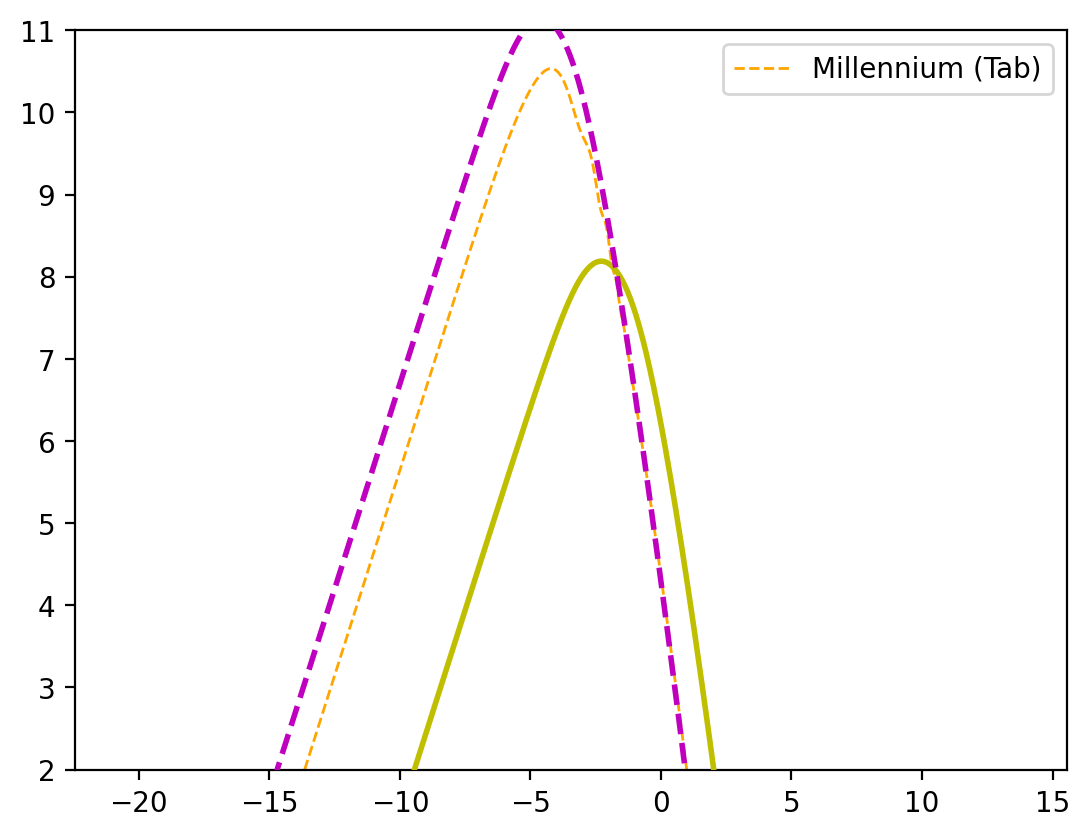

In [317]:
# In this cell we test BBKS

lf = np.log

h = 0.1
omega0 = 1
new_sigma_8 = 1.0

pl.plot(lf(d_mil_tab[:,0]),lf(d_mil_tab[:,1]),label='Millennium (Tab)',c='orange',ls='--',lw=1)

# A "reference" cosmology with h=1, Om0=1, no baryons, sigma8=1
lcdm_ref   = cmo.FlatLambdaCDM(100,1.0,Ob0=0.0,Tcmb0=0)
T_bbks_ref = hmf.density_field.transfer.Transfer(cosmo_model=lcdm_ref,
                                             sigma_8=1.0,n=1,
                                             transfer_model=hmf.density_field.transfer_models.BBKS)

lcdm_mil   = cmo.FlatLambdaCDM(100*h,omega0,Ob0=0.0,Tcmb0=0)
T_bbks_mil = hmf.density_field.transfer.Transfer(cosmo_model=lcdm_mil,
                                             sigma_8=new_sigma_8,n=1,
                                             transfer_model=hmf.density_field.transfer_models.BBKS)

lcdm_mil_b   = cmo.FlatLambdaCDM(100*h,omega0,Ob0=0.045,Tcmb0=2.73)
T_bbks_mil_b = hmf.density_field.transfer.Transfer(cosmo_model=lcdm_mil_b,
                                             sigma_8=new_sigma_8,n=1,
                                             transfer_model=hmf.density_field.transfer_models.BBKS)

pl.plot(np.log(T_bbks_ref.k),
        np.log(T_bbks_ref.power),
        c='y',lw=2,zorder=20,alpha=1)

scale = ((new_sigma_8/T_bbks_ref.sigma_8)**2)
print(scale)

gamma = omega0*h**2

pl.plot(np.log(T_bbks_ref.k) + np.log(gamma/h),
        np.log(T_bbks_ref.power) + np.log(Z) - np.log10(h**3),
        c='y',lw=2,zorder=25,alpha=1, ls=':')

pl.plot(np.log(T_bbks_mil.k),
        np.log(T_bbks_mil.power),
        c='m',lw=2,zorder=20,alpha=1, ls='--');

# Baryons
#pl.plot(np.log(T_bbks_mil_b.k),
#        np.log(T_bbks_mil_b.power),
#        c='c',lw=2,zorder=20,alpha=1, ls='--')

#pl.plot(np.log(T_bbks_ref.k),np.log(T_bbks_ref._unnormalised_power),
#        c='m',lw=2,zorder=20,alpha=1)

pl.legend();
pl.ylim(2,11)

In [311]:
Z = 1.0/(np.exp(T_bbks_mil.transfer.lnt(np.log(gamma)))/np.exp(T_bbks.transfer.lnt(np.log(1))))**2

In [307]:
Z

0.08855449625881148

In [266]:
(T_bbks_mil._power0.max()/T_bbks._power0.max())/gamma

0.42006989847196213

In [267]:
kh.value/h

4.7652013599736006e-07

In [224]:
(T_bbks_mil._unn_sig8.max()/T_bbks._unn_sig8.max())**2

0.2417089369633264

In [230]:
gamma

0.010000000000000002

In [228]:
3.0244443458062484/0.2417089369633264

12.51275349518887

In [181]:
(np.log(T_bbks_ref.power.max()) - np.log(T_bbks_mil.power.max()))/np.log(gamma)

0.6412773899514385

In [159]:
import astropy.constants as const

In [161]:
kh = (100*u.km/u.s)/const.c

In [165]:
gamma

0.010000000000000002

In [170]:
np.log(kh/h)

<Quantity -5.70309043>

In [39]:
T_bbks_ref._unn_sig8

0.0032793305832278497

In [297]:
np.log(0.25/(gamma**2))

2.015715850799291

(2.0, 11.0)

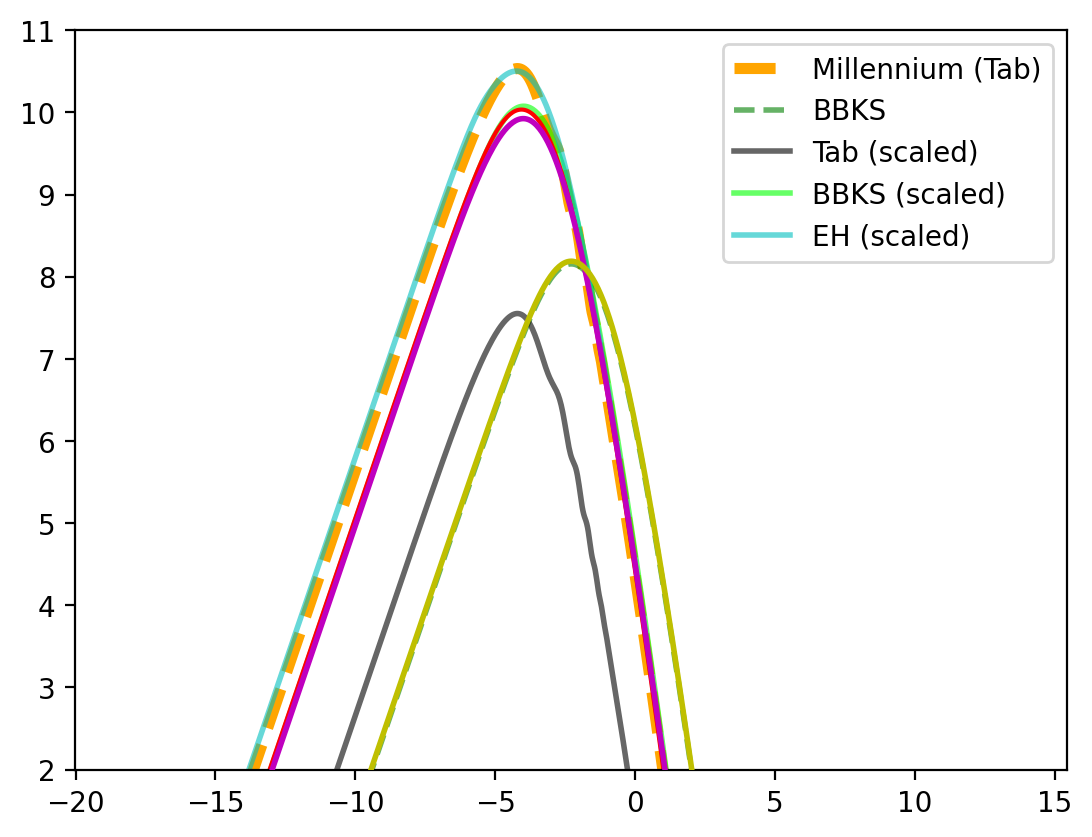

In [301]:
lf = np.log

pl.plot(lf(d_mil_tab[:,0]),lf(d_mil_tab[:,1]),label='Millennium (Tab)',c='orange',ls='--',lw=4)

#pl.plot(lf(k_eh), lf(pk_eh), c='b',    label='EH', ls='--',alpha=0.6,lw=2)
pl.plot(lf(k_bb), lf(pk_bb)+np.log(1/(gamma**2)), c='g',    label='BBKS',ls='--',alpha=0.6,lw=2)
#pl.plot(lf(k_tb), lf(pk_tb), c='r',    label='Tabulated',alpha=0.6,lw=2)

# S = sigma8/sigma_*
#S = 0.340618610

#pl.plot(lf(k_eh) + lf(gamma), lf(pk_eh)+2*lf(scla_eh)    + 3*lf(gamma),   c='c', label='EH (scaled)',ls='solid',alpha=0.6,lw=2)


pl.plot(lf(k_tb),             lf(pk_tb)+2*lf(scla_mil), 
        c='k', label='Tab (scaled)',ls='solid',alpha=0.6,lw=2)

pl.plot(lf(k_bb) + lf(gamma), lf(pk_bb)+2*lf(scla_bbks)-4.85*lf(gamma), 
        c='lime', label='BBKS (scaled)',ls='solid',alpha=0.6,lw=2)

pl.plot(lf(k_eh) + lf(gamma), lf(pk_eh)+2*lf(scla_eh)-4.85*lf(gamma),   
        c='c', label='EH (scaled)',ls='solid',alpha=0.6,lw=2)

#pl.plot(lf(k_bb) + lf(gamma)-0.3, lf(pk_bb)+2*lf(scla_bbks)  - 3*lf(gamma)+0.5, c='lime', label='BBKS (scaled)',ls='--',alpha=0.6,lw=2)

# Answers from HMF (agrees with Millennium)
pl.plot(np.log(T_bbks.k),np.log(T_bbks.power),
        c='r')

#pl.plot(np.log(T_bbksb.k),np.log(T_bbksb.power),
#        c='purple')

#pl.plot(np.log(T_eh.k),np.log(T_eh.power),
#        c='pink')

pl.plot(np.log(T_eh.k),np.log(T_eh.power),
        c='m',lw=2,zorder=20,alpha=1)

pl.plot(np.log(T_bbks_ref.k),np.log(T_bbks_ref.power),
        c='y',lw=2,zorder=20,alpha=1)

pl.legend()
pl.ylim(2,11)

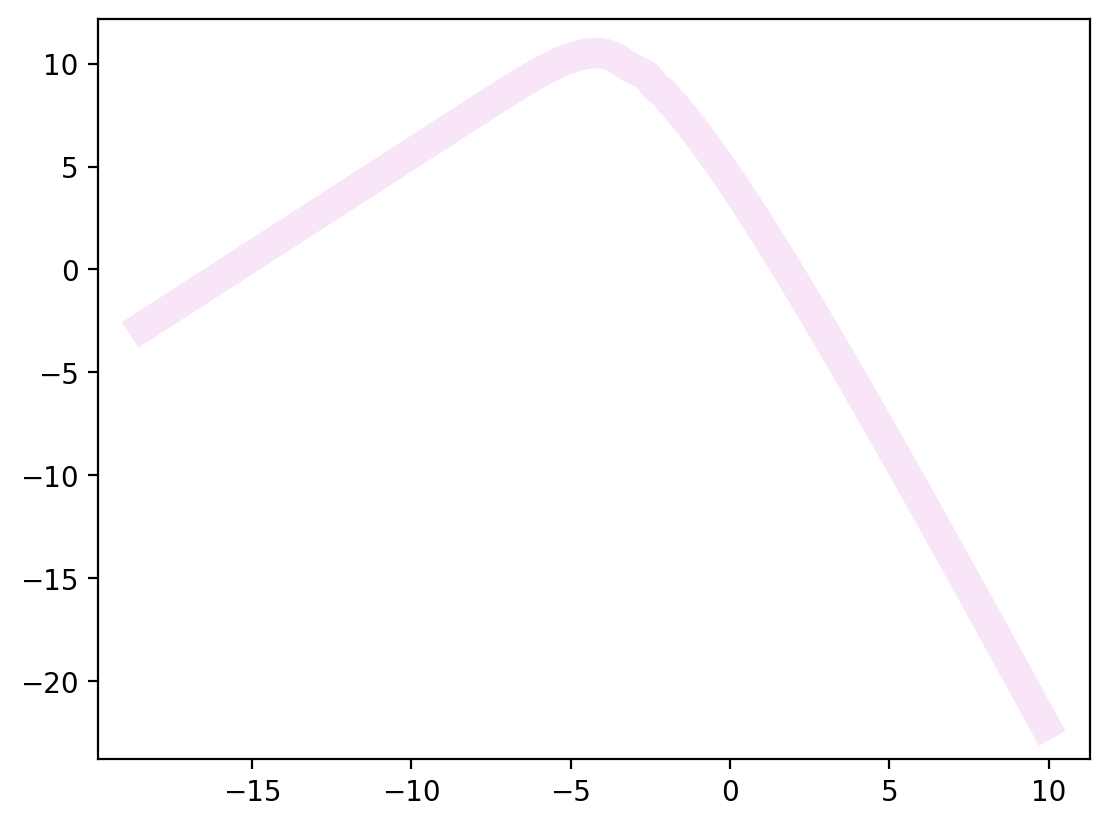

In [260]:
pl.plot(np.log(T_ehb.k),np.log(T_ehb.power),
        c='m',lw=11,zorder=-10,alpha=0.1)

In [145]:
hmf.density_field.transfer.Transfer.get_all_parameter_defaults()

{'cosmo_model': FlatLambdaCDM(name='Planck18', H0=<Quantity 67.66 km / (Mpc s)>, Om0=0.30966, Tcmb0=<Quantity 2.7255 K>, Neff=3.046, m_nu=<Quantity [0.  , 0.  , 0.06] eV>, Ob0=0.04897),
 'cosmo_params': {},
 'n': 0.9667,
 'sigma_8': 0.8159,
 'growth_params': {'dlna': 0.01, 'amin': 1e-08},
 'lnk_min': -18.420680743952364,
 'lnk_max': 9.903487552536127,
 'dlnk': 0.05,
 'z': 0.0,
 'transfer_model': hmf.density_field.transfer_models.CAMB,
 'transfer_params': {'camb_params': None,
  'dark_energy_params': {},
  'extrapolate_with_eh': None,
  'kmax': None},
 'takahashi': True,
 'growth_model': hmf.cosmology.growth_factor.GrowthFactor}

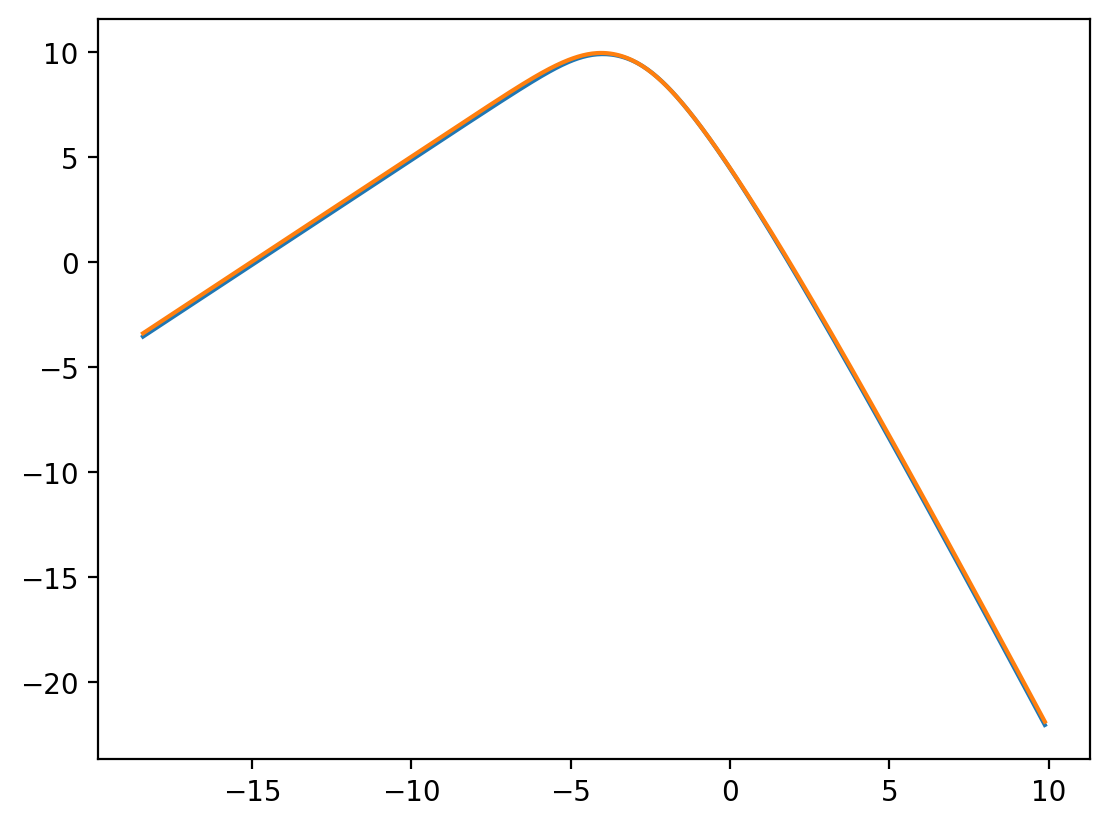

In [148]:
pl.plot(np.log(T_bbks.k),np.log(T_bbks.power))
pl.plot(np.log(T_eh.k),np.log(T_eh.power))

In [273]:
cc = lcdm_nob
Gamma = cc.Om0 * cc.h
q = ( 1 / Gamma * np.exp(cc.Ob0 + np.sqrt(2 * cc.h) * cc.Ob0 / cc.Om0) )

In [274]:
Gamma

0.1825

In [281]:
1/gamma

5.47945205479452

In [276]:
q

5.47945205479452

(-8.0, -1.0)

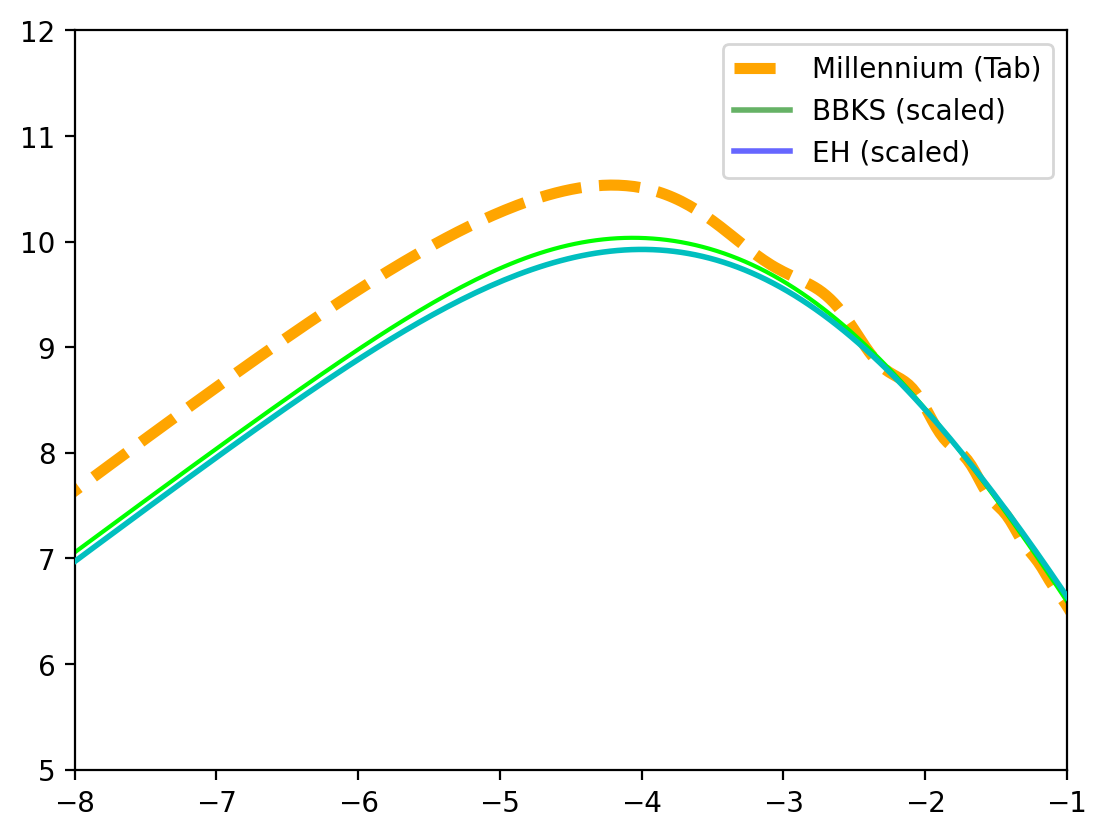

In [270]:

lf = np.log

pl.plot(lf(d_mil_tab[:,0]),lf(d_mil_tab[:,1]),label='Millennium (Tab)',c='orange',ls='--',lw=4)

#pl.plot(lf(k_eh), lf(pk_eh), c='b',    label='EH', ls='--',alpha=0.6,lw=2)
#pl.plot(lf(k_bb), lf(pk_bb), c='g',    label='BBKS',ls='--',alpha=0.6,lw=2)
#pl.plot(lf(k_tb), lf(pk_tb), c='r',    label='Tabulated',alpha=0.6,lw=2)

# S = sigma8/sigma_*
#S = 0.340618610

pl.plot(lf(k_bb) + lf(gamma)-0.05, lf(pk_bb)+2*lf(scla_bbks), 
        c='g', label='BBKS (scaled)',ls='solid',alpha=0.6,lw=2)

pl.plot(lf(k_eh) + lf(gamma)-0.05, lf(pk_eh)+2*lf(scla_eh),   
        c='b', label='EH (scaled)',ls='solid',alpha=0.6,lw=2)

# pl.plot(k_eh + np.log(gamma), pk_eh - 2*np.log((gamma**3)/omega0) - np.log(np.sqrt(2)*np.pi), c='m', label='EH (scaled)',ls='solid',alpha=0.6,lw=2)

# Answers from HMF (agrees with Millennium)
pl.plot(np.log(T_bbks.k),np.log(T_bbks.power),
        c='lime')

#pl.plot(np.log(T_bbksb.k),np.log(T_bbksb.power),
#        c='purple')

#pl.plot(np.log(T_eh.k),np.log(T_eh.power),
#        c='pink')

pl.plot(np.log(T_eh.k),np.log(T_eh.power),
        c='c',lw=2,zorder=20,alpha=1)

pl.legend()
pl.ylim(5,12)
pl.xlim(-8,-1)

In [47]:
5.5*2

11.0

In [46]:
nspec=1
(-(nspec+3.0)/6.0)

-0.6666666666666666